# India Weather Analysis & Prediction
## 1: Data Collection & Cleaning

**Goal:** Download daily weather data from 1981 up to the latest available day (2026) for major Indian cities from NASA POWER, clean it, and save an analysis-ready dataset.

**Data source:** [NASA POWER API](https://power.larc.nasa.gov/)

**Variables:** mean/max/min temperature, rainfall, humidity, wind speed, surface pressure

## 1. Setup

In [1]:
import json
import time
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

# Folders for raw and processed data
DATA_RAW = Path("data/raw")
DATA_PROC = Path("data/processed")
for p in (DATA_RAW, DATA_PROC):
    p.mkdir(parents=True, exist_ok=True)

## 2. Configuration
Cities are chosen to cover India's different climate zones. Add or remove cities freely.

In [2]:
CITIES = {
    # city: (latitude, longitude)  -> climate zone
    "Delhi":     (28.61, 77.21),   # Semi-arid, extreme summers & cold winters
    "Mumbai":    (19.08, 72.88),   # Tropical coastal, heavy monsoon
    "Chennai":   (13.08, 80.27),   # Tropical coastal, NE monsoon
    "Kolkata":   (22.57, 88.36),   # Humid subtropical
    "Bengaluru": (12.97, 77.59),   # Plateau, moderate climate
    "Hyderabad": (17.38, 78.48),   # Semi-arid tropical
    "Jaipur":    (26.91, 75.79),   # Hot semi-arid / desert edge
    "Shimla":    (31.10, 77.17),   # Himalayan, cold
}

START = "19810101"
# NASA POWER lags a few days behind, so we stop 7 days before today
END = (date.today() - timedelta(days=7)).strftime("%Y%m%d")
CURRENT_YEAR = date.today().year   # partial year: excluded from yearly trend stats
print(f"Downloading {START} -> {END}")

PARAMETERS = "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M,PS"
BASE_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

COLUMN_NAMES = {
    "T2M": "temp_mean",
    "T2M_MAX": "temp_max",
    "T2M_MIN": "temp_min",
    "PRECTOTCORR": "rainfall_mm",
    "RH2M": "humidity_pct",
    "WS2M": "wind_speed_ms",
    "PS": "pressure_kpa",
}

## 3. Download data
Results are cached in `data/raw/`, so re-running the notebook won't hit the API again.

In [3]:
def fetch_city(city, lat, lon, retries=3):
    """Download daily data for one city (with caching and retries)."""
    cache_file = DATA_RAW / f"{city.lower()}_{START}_{END}.json"
    if cache_file.exists():
        print(f"✔ {city}: loaded from cache")
        return json.loads(cache_file.read_text())

    query = {
        "parameters": PARAMETERS,
        "community": "RE",
        "latitude": lat,
        "longitude": lon,
        "start": START,
        "end": END,
        "format": "JSON",
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(BASE_URL, params=query, timeout=180)
            r.raise_for_status()
            data = r.json()
            cache_file.write_text(json.dumps(data))
            print(f"⬇ {city}: downloaded")
            return data
        except requests.RequestException as e:
            print(f"⚠ {city}: attempt {attempt} failed ({e})")
            time.sleep(5 * attempt)
    raise RuntimeError(f"Could not download data for {city}")


def to_dataframe(city, data):
    """Convert the API JSON into a tidy DataFrame."""
    df = pd.DataFrame(data["properties"]["parameter"])
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df.index.name = "date"
    df.insert(0, "city", city)
    return df.reset_index()

In [4]:
frames = []
for city, (lat, lon) in CITIES.items():
    raw = fetch_city(city, lat, lon)
    frames.append(to_dataframe(city, raw))

df = pd.concat(frames, ignore_index=True)
df = df.rename(columns=COLUMN_NAMES)
print(f"\nTotal rows: {len(df):,}")
df.head()

✔ Delhi: loaded from cache
✔ Mumbai: loaded from cache
✔ Chennai: loaded from cache
✔ Kolkata: loaded from cache
✔ Bengaluru: loaded from cache
✔ Hyderabad: loaded from cache
✔ Jaipur: loaded from cache
✔ Shimla: loaded from cache

Total rows: 133,816


,date,city,temp_mean,temp_max,temp_min,rainfall_mm,humidity_pct,wind_speed_ms,pressure_kpa
0,1981-01-01,Delhi,14.40,23.99,7.59,0.00,51.15,2.85,99.10
1,1981-01-02,Delhi,15.63,24.38,7.94,0.00,50.83,1.26,99.02
2,1981-01-03,Delhi,18.07,26.37,9.48,36.24,45.63,1.41,98.87
3,1981-01-04,Delhi,17.20,24.97,9.94,282.48,55.28,1.54,98.87
4,1981-01-05,Delhi,15.98,23.74,9.95,0.48,57.97,1.27,98.85


## 4. Clean the data
NASA POWER marks missing values as `-999`. We convert those to `NaN`, check how much is missing, and fill only *short* gaps (up to 3 days) by interpolation.

In [5]:
value_cols = list(COLUMN_NAMES.values())

# 1. Replace the -999 missing marker
df[value_cols] = df[value_cols].replace(-999, np.nan)

# 2. Report missing values
missing = df[value_cols].isna().sum()
print("Missing values before filling:")
print(missing[missing > 0] if missing.sum() else "None 🎉")

Missing values before filling:
None 🎉


In [6]:
# 3. Fill short gaps only (per city, time-ordered)
df = df.sort_values(["city", "date"]).reset_index(drop=True)
df[value_cols] = (
    df.groupby("city")[value_cols]
      .transform(lambda s: s.interpolate(limit=3, limit_area="inside"))
)

# 4. Basic quality checks
assert not df.duplicated(["city", "date"]).any(), "Duplicate city-date rows found"

bad_range = (df["temp_min"] > df["temp_max"]).sum()
print(f"Rows where temp_min > temp_max: {bad_range}")

neg_rain = (df["rainfall_mm"] < 0).sum()
print(f"Rows with negative rainfall: {neg_rain}")

print("\nRemaining missing values:", int(df[value_cols].isna().sum().sum()))

Rows where temp_min > temp_max: 0
Rows with negative rainfall: 0

Remaining missing values: 0


## 5. Add helpful date features

In [7]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_year"] = df["date"].dt.dayofyear

# Indian meteorological seasons
def season(m):
    if m in (3, 4, 5):
        return "Summer"
    if m in (6, 7, 8, 9):
        return "Monsoon"
    if m in (10, 11):
        return "Post-monsoon"
    return "Winter"

df["season"] = df["month"].map(season)
df.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_13348\1872597247.py:3: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["date"].dt.dayofyear


,date,city,temp_mean,temp_max,temp_min,rainfall_mm,humidity_pct,wind_speed_ms,pressure_kpa,year,month,day_of_year,season
0,1981-01-01,Bengaluru,21.00,29.10,14.62,0.00,68.68,2.85,91.90,1981,1,1,Winter
1,1981-01-02,Bengaluru,21.53,29.12,15.58,10.08,69.01,1.91,91.87,1981,1,2,Winter
2,1981-01-03,Bengaluru,21.14,29.07,16.04,20.64,68.67,2.41,91.88,1981,1,3,Winter
3,1981-01-04,Bengaluru,20.84,29.33,15.24,0.00,64.00,2.23,91.90,1981,1,4,Winter
4,1981-01-05,Bengaluru,20.61,30.22,13.77,0.00,62.44,1.73,91.93,1981,1,5,Winter


## 6. Quick look at the data

In [8]:
df.groupby("city")[["temp_mean", "temp_max", "temp_min", "rainfall_mm", "humidity_pct"]].describe().T.round(2)

city                Bengaluru   Chennai     Delhi  Hyderabad    Jaipur  \
temp_mean    count   16727.00  16727.00  16727.00   16727.00  16727.00   
             mean       23.68     27.89     25.61      26.01     25.53   
             std         2.91      2.67      7.71       4.22      6.98   
             min        15.36     21.11      6.95      15.30      8.45   
             25%        21.87     25.76     18.84      23.25     19.69   
             50%        23.21     28.08     26.88      25.37     26.85   
             75%        25.30     29.89     31.64      28.56     30.87   
             max        32.86     35.33     41.81      38.09     39.57   
temp_max     count   16727.00  16727.00  16727.00   16727.00  16727.00   
             mean       30.25     32.26     33.12      32.40     33.01   
             std         3.79      3.55      7.07       4.78      6.31   
             min        20.15     22.99     12.55      20.74     12.97   
             25%        27.30     29.09     27.73      28.78     28.39   
             50%        29.48     32.27     32.92      30.92     33.10   
             75%        32.86     35.06     38.39      35.83     37.73   
             max        40.78     43.34     49.29      45.53     47.84   
temp_min     count   16727.00  16727.00  16727.00   16727.00  16727.00   
             mean       18.38     24.55     19.07      20.58     19.15   
             std         2.87      2.39      8.11       4.13      7.36   
             min         7.05     17.16     -1.36       8.09      1.05   
             25%        16.79     22.92     11.80      17.48     12.82   
             50%        19.01     24.99     20.12      21.53     20.36   
             75%        20.22     26.13     26.17      23.09     25.30   
             max        27.19     31.07     35.13      32.23     34.01   
rainfall_mm  count   16727.00  16727.00  16727.00   16727.00  16727.00   
             mean       55.87     81.36     49.91      55.54     36.21   
             std       147.83    216.55    160.19     157.92    121.73   
             min         0.00      0.00      0.00       0.00      0.00   
             25%         0.00      0.00      0.00       0.00      0.00   
             50%         3.36      6.00      0.00       0.48      0.00   
             75%        40.80     62.16     16.08      31.20      7.44   
             max      5735.76   4509.12   3216.96    3269.52   2489.76   
humidity_pct count   16727.00  16727.00  16727.00   16727.00  16727.00   
             mean       67.86     72.33     44.56      60.95     40.59   
             std        16.29      9.12     21.36      20.81     21.16   
             min        15.05     39.84      3.66       5.03      4.97   
             25%        56.75     65.55     27.78      43.25     23.42   
             50%        72.55     72.57     41.13      65.49     35.51   
             75%        80.50     79.31     60.20      79.13     56.12   
             max        95.77     94.08     95.15      95.47     93.18   

city                 Kolkata    Mumbai    Shimla  
temp_mean    count  16727.00  16727.00  16727.00  
             mean      25.93     26.65     21.09  
             std        4.88      2.87      6.93  
             min       10.90     16.47      4.44  
             25%       22.30     24.93     14.91  
             50%       27.61     26.34     22.18  
             75%       29.19     28.50     26.48  
             max       37.25     36.44     36.81  
temp_max     count  16727.00  16727.00  16727.00  
             mean      31.58     32.74     27.66  
             std        4.76      4.15      6.53  
             min       16.85     23.48      8.06  
             25%       28.60     29.28     22.58  
             50%       31.06     31.71     27.91  
             75%       34.28     36.16     32.19  
             max       46.92     46.11     43.97  
temp_min     count  16727.00  16727.00  16727.00  
             mean      21.21     22.06     15.8

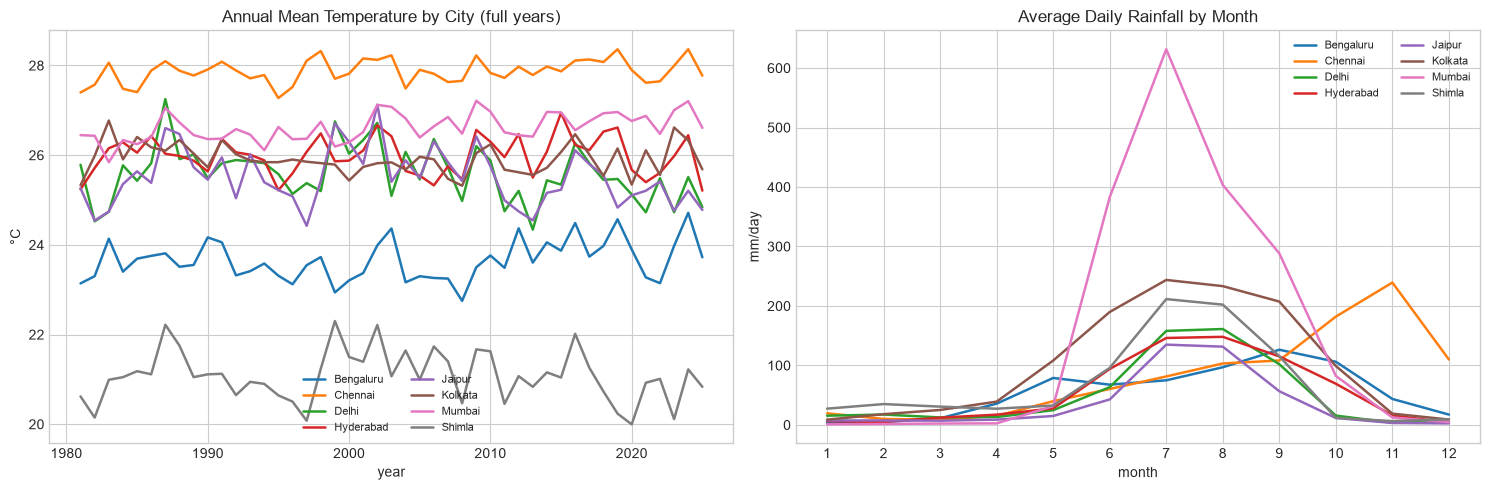

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Annual mean temperature per city
full_years = df[df["year"] < CURRENT_YEAR]   # drop partial current year
annual = full_years.pivot_table(index="year", columns="city", values="temp_mean", aggfunc="mean")
annual.plot(ax=axes[0], lw=1.8)
axes[0].set_title("Annual Mean Temperature by City (full years)")
axes[0].set_ylabel("°C")
axes[0].legend(ncol=2, fontsize=8)

# Average monthly rainfall per city
monthly_rain = df.pivot_table(index="month", columns="city", values="rainfall_mm", aggfunc="mean")
monthly_rain.plot(ax=axes[1], lw=1.8)
axes[1].set_title("Average Daily Rainfall by Month")
axes[1].set_ylabel("mm/day")
axes[1].set_xticks(range(1, 13))
axes[1].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

## 7. Save the clean dataset

In [10]:
out_path = DATA_PROC / "india_weather_daily.csv"
df.to_csv(out_path, index=False)
print(f"Saved: {out_path}  ({out_path.stat().st_size / 1e6:.1f} MB)")

# Optional: download it from Colab
# from google.colab import files
# files.download(str(out_path))

Saved: data\processed\india_weather_daily.csv  (10.5 MB)
